In [2]:
import pandas as pd
import numpy as np
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path
import os
from pathlib import Path
import sys


from vis.utils_motifs import motif_to_fwords

### 1. Folder and file definitions
Based on the threshold analysis in threshold_analysis.ipynb, we choose the threshold of ... % and use this throughout the entire analysis in this file.

In [3]:
RESULT_DIR = Path("../results/oct24_GCN_train_50w_wan-w5_nf-emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2029")
motif_file = RESULT_DIR / "noob_motcom040.csv" 
results_file = RESULT_DIR / "explanations_none_object.pth"

motifs_per_row = RESULT_DIR / "noob_mot2edg040.pth"

function_words_file = Path("../data/function_words.txt")

In [4]:
function_words = function_words_file.read_text(encoding="utf-8").split()

In [5]:
# This file contains analysis of (2-edge) motifs that occur in human samples and machine samples
# motif - tuple of edges
# human_present - correctly classified human graphs where motif exists in the original WAN
# human_selected - -||- (top % fraction)
# human_rate - human_selected / human_present
# machine_present, machine_selected, machine_rate analogously
# difference - machine_rate-human_rate\n",


df_motifs = pd.read_csv(motif_file)
df_motifs

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference
0,"((113, 67), (113, 198))",1,1,1.0,1,0,0.0,-1.0
1,"((31, 240), (240, 31))",1,0,0.0,1,1,1.0,1.0
2,"((158, 76), (158, 198))",1,0,0.0,1,1,1.0,1.0
3,"((83, 36), (114, 83))",1,0,0.0,1,1,1.0,1.0
4,"((31, 215), (31, 224))",1,0,0.0,1,1,1.0,1.0
...,...,...,...,...,...,...,...,...
19402,"((273, 158), (273, 198))",1,1,1.0,0,0,NaN,NaN
19403,"((273, 158), (273, 256))",1,1,1.0,0,0,NaN,NaN
19404,"((273, 163), (273, 198))",1,1,1.0,0,0,NaN,NaN
19405,"((273, 165), (273, 256))",1,1,1.0,0,0,NaN,NaN


In [6]:
import ast
import pandas as pd

df_motifs["function_words"] = pd.Series(
    [None] * len(df_motifs),
    index=df_motifs.index,
    dtype=object
)

def convert_motif(motif):
    if isinstance(motif, str):
        motif = ast.literal_eval(motif)

    motif_1, motif_2 = motif

    words_1 = motif_to_fwords(motif_1, function_words)

    words_2 = motif_to_fwords(motif_2, function_words)

    return (words_1, words_2)

for idx, row in df_motifs.iterrows():
    df_motifs.at[idx, "function_words"] = convert_motif(row["motif"])

df_motifs.head()

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference,function_words
0,"((113, 67), (113, 198))",1,1,1.0,1,0,0.0,-1.0,"((is, even), (is, the))"
1,"((31, 240), (240, 31))",1,0,0.0,1,1,1.0,1.0,"((as, well), (well, as))"
2,"((158, 76), (158, 198))",1,0,0.0,1,1,1.0,1.0,"((on, for), (on, the))"
3,"((83, 36), (114, 83))",1,0,0.0,1,1,1.0,1.0,"((has, been), (it, has))"
4,"((31, 215), (31, 224))",1,0,0.0,1,1,1.0,1.0,"((as, they), (as, to))"


In [7]:
# Get the top entries where human_rate >0.5 and machine_rate<0.5

df_human_rate = df_motifs.loc[
    (df_motifs["human_rate"] > 0.5) &
    (df_motifs["machine_rate"] < 0.5) &
    (df_motifs["human_present"] > df_motifs["machine_present"]),
    ["function_words", "human_rate", "human_present", "machine_present"]
].copy()

df_human_rate = df_human_rate.reset_index(drop=True)
df_human_rate["percentage_present"] = df_human_rate["human_present"]*100 / 360

df_human_rate

,function_words,human_rate,human_present,machine_present,percentage_present
0,"((at, a), (is, a))",1.000000,3,1,0.833333
1,"((at, a), (to, a))",1.000000,3,2,0.833333
2,"((on, a), (that, a))",1.000000,3,1,0.833333
3,"((on, a), (to, a))",1.000000,2,1,0.555556
4,"((be, of), (of, be))",1.000000,2,1,0.555556
...,...,...,...,...,...
117,"((are, to), (you, are))",0.571429,7,1,1.944444
118,"((of, and), (the, and))",0.571429,7,6,1.944444
119,"((and, the), (the, and))",0.545455,11,6,3.055556
120,"((that, should), (that, the))",0.600000,5,4,1.388889


In [8]:
# Get the top entries where machine_rate >0.5 and human_rate<0.5

df_machine_rate = df_motifs.loc[
    (df_motifs["machine_rate"] > 0.5) &
    (df_motifs["human_rate"] < 0.5) &
    (df_motifs["human_present"] < df_motifs["machine_present"]),
    ["function_words", "machine_rate", "machine_present", "human_present"]
].copy()

df_machine_rate["percentage_present"] = df_machine_rate["machine_present"]*100 / 360
df_machine_rate = df_machine_rate.reset_index(drop=True)

df_machine_rate

,function_words,machine_rate,machine_present,human_present,percentage_present
0,"((as, an), (as, they))",1.000000,2,1,0.555556
1,"((has, and), (the, has))",1.000000,2,1,0.555556
2,"((on, that), (that, the))",1.000000,2,1,0.555556
3,"((as, a), (as, and))",1.000000,2,1,0.555556
4,"((is, it), (it, that))",1.000000,2,1,0.555556
...,...,...,...,...,...
67,"((in, of), (the, of))",0.555556,9,5,2.500000
68,"((of, to), (the, of))",0.555556,9,4,2.500000
69,"((and, the), (the, of))",0.538462,13,8,3.611111
70,"((should, be), (the, should))",0.900000,10,7,2.777778


### 2. Summary motifs

In [9]:
human_selected = df_motifs["human_selected"] > 0
machine_selected = df_motifs["machine_selected"] > 0

human_only = (human_selected & ~machine_selected).sum()
machine_only = (~human_selected & machine_selected).sum()
shared = (human_selected & machine_selected).sum()

total = (human_selected | machine_selected).sum()

print(f"Total unique selected motifs: {total}")
print(f"Human only: {human_only}")
print(f"Machine only: {machine_only}")
print(f"Shared: {shared}")

Total unique selected motifs: 19407
Human only: 14654
Machine only: 4568
Shared: 185


In [10]:
h = df_motifs[
    (df_motifs["human_selected"] > 0) &
    (df_motifs["machine_selected"] == 0)
]

m = df_motifs[
    (df_motifs["human_selected"] == 0) &
    (df_motifs["machine_selected"] > 0)
]

print("Human-only motifs selected once (uniqe motifs within the human class):",
      (h["human_selected"] == 1).sum())

print("Amount of non-unique motifs within the human class: ",
      human_only - (h["human_selected"] == 1).sum())

print("Machine-only motifs selected once (unique motifs within the machine class):",
      (m["machine_selected"] == 1).sum())

print("Amount of non-unique motifs within the machine class: ",
      machine_only - (m["machine_selected"] == 1).sum())

Human-only motifs selected once (uniqe motifs within the human class): 13331
Amount of non-unique motifs within the human class:  1323
Machine-only motifs selected once (unique motifs within the machine class): 3899
Amount of non-unique motifs within the machine class:  669


In [11]:
results = torch.load(
    results_file,
    map_location="cpu",
    weights_only=False
)

In [12]:
df_explanations = pd.DataFrame([
    {
        "row": result["row"],
        "label": result["label"],
        "pred": result["pred"]
    }
    for result in results
])

# Count unique graphs per class
graph_counts = (
    df_explanations
    .groupby("label")["row"]
    .nunique()
)

print("Number of graphs per class:")
print(graph_counts)

print("Total unique graphs:", df_explanations["row"].nunique())

Number of graphs per class:
label
0    180
1    180
Name: row, dtype: int64
Total unique graphs: 360


In [13]:
df_correct = df_explanations[
    df_explanations["label"] == df_explanations["pred"]
]

n_human_graphs = df_correct[
    df_correct["label"] == 0
]["row"].nunique()

n_machine_graphs = df_correct[
    df_correct["label"] == 1
]["row"].nunique()

print("Correctly classified human graphs:", n_human_graphs)
print("Correctly classified machine graphs:", n_machine_graphs)

Correctly classified human graphs: 162
Correctly classified machine graphs: 174


### 3. How motifs affect the prediction?


In [14]:
# Get a dataframe with top highest masked motifs chosen per sample in the test set

import torch

data = torch.load(motifs_per_row, map_location="cpu", weights_only=False)
data = [
    {
        key: value.cpu().numpy() if isinstance(value, torch.Tensor) else value
        for key, value in item.items()
    }
    for item in data
]

df_motifs_per_sample = pd.DataFrame(data)

# And get only the ones that were correctly predicted (label == prediction)
df_motifs_per_sample = df_motifs_per_sample.loc[
    df_motifs_per_sample["pred"] == df_motifs_per_sample["label"]
].copy()

df_motifs_per_sample = df_motifs_per_sample.reset_index(drop=True)
df_motifs_per_sample

,row,label,pred,motifs,num_motifs
0,13,0,0,"[((0, 21), (21, 35)), ((0, 21), (21, 55)), ((0...",59
1,17,0,0,"[((0, 56), (0, 150)), ((0, 56), (0, 152)), ((0...",121
2,20,0,0,"[((0, 154), (0, 220)), ((0, 154), (122, 154)),...",125
3,22,0,0,"[((0, 29), (55, 0)), ((0, 29), (74, 29)), ((0,...",59
4,28,0,0,"[((0, 21), (0, 108)), ((0, 21), (0, 224)), ((0...",80
...,...,...,...,...,...
331,2372,1,1,"[((21, 197), (21, 224)), ((21, 197), (215, 21)...",24
332,2379,1,1,"[((0, 36), (0, 83)), ((0, 36), (113, 0)), ((0,...",50
333,2381,1,1,"[((15, 8), (197, 8)), ((16, 136), (224, 136)),...",74
334,2383,1,1,"[((112, 21), (112, 83)), ((112, 21), (266, 112...",11


In [15]:
metrics_analysis_path = RESULT_DIR / "noob_motfaith040_50.csv"

# One row = one (test graph, 2-edge motif) pair.
# The motif is one of the pairs of adjacent directed edges found in the
# explainer's top edges of that graph. Its two edges are perturbed on their own
# and compared with random controls of the same size (2 edges).
# Only correctly classified graphs with at least one motif produce rows.
# A graph with 30 motifs gives 30 rows.

# Identification columns
#   row                  graph id (data.idx), same as "row" in predictions.csv.
#                        Several rows share it, one per motif in that graph.
#   class                "Human" (label 0) or "Machine" (label 1).
#   motif                tuple of two directed edges, e.g. ((3, 17), (17, 42)).
#                        Node indices map to words via fwords.
#   has_self_loop        1 if one of the two edges is a self-loop (u, u), else 0.
#   mean_edge_mask       mean explainer mask score of the motif's two edges in
#                        this graph. Higher = explainer found it more important.
#   original_confidence  softmax probability of the predicted class on the full
#                        graph. Same for all rows of one graph; reference for
#                        every drop below.
#
# Motif perturbation columns
#   comprehensiveness    original_confidence minus confidence after REMOVING only
#                        the motif's two edges. Higher = model relied on them.
#   sufficiency          original_confidence minus confidence after KEEPING ONLY
#                        the motif's two edges. Lower = they carry the evidence.
#                        With 2 edges left the graph is almost empty, so expect
#                        large values; compare with the controls.
#   flip_removed         1 if removing the motif changed the predicted class.
#   flip_only            1 if keeping only the motif changed the predicted class.
#
# Control columns (each averaged over random_repeats random draws in the same graph)
#   *_random_pair        two random edges from the graph.
#   *_random_adjacent    two random edges sharing a node (the fair control,
#                        since motifs are also adjacent pairs).
#   Columns: comprehensiveness_random_pair, sufficiency_random_pair,
#            flip_removed_random_pair, flip_only_random_pair, and the same four
#            with _random_adjacent. Flip controls are fractions in [0, 1].

In [16]:
df_metrics_per_sample_per_motif = pd.read_csv(metrics_analysis_path)

df_metrics_per_sample_per_motif["function_words"] = pd.Series(
    [None] * len(df_metrics_per_sample_per_motif),
    index=df_metrics_per_sample_per_motif.index,
    dtype=object
)


for idx, row in df_metrics_per_sample_per_motif.iterrows():
    df_metrics_per_sample_per_motif.at[idx, "function_words"] = convert_motif(row["motif"])

df_metrics_per_sample_per_motif

,row,class,motif,has_self_loop,mean_edge_mask,original_confidence,comprehensiveness,sufficiency,flip_removed,flip_only,comprehensiveness_random_pair,sufficiency_random_pair,flip_removed_random_pair,flip_only_random_pair,comprehensiveness_random_adjacent,sufficiency_random_adjacent,flip_removed_random_adjacent,flip_only_random_adjacent,function_words
0,13,Human,"((0, 21), (21, 35))",0,0.704492,0.992357,-0.003342,0.899153,0,1,0.001346,0.882754,0.0,0.94,0.001334,0.906652,0.0,1.00,"((a, and), (and, because))"
1,13,Human,"((0, 21), (21, 55))",0,0.762613,0.992357,-0.001949,0.946663,0,1,0.000888,0.909918,0.0,1.00,0.002456,0.891396,0.0,0.96,"((a, and), (and, do))"
2,13,Human,"((0, 21), (21, 150))",0,0.728355,0.992357,-0.002444,0.940860,0,1,0.000637,0.898094,0.0,0.98,0.000558,0.906822,0.0,1.00,"((a, and), (and, not))"
3,13,Human,"((0, 21), (154, 21))",0,0.764471,0.992357,-0.002400,0.957480,0,1,0.000931,0.892921,0.0,1.00,0.000365,0.903150,0.0,1.00,"((a, and), (of, and))"
4,13,Human,"((8, 32), (8, 108))",0,0.769676,0.992357,0.003255,0.915363,0,1,0.000030,0.907288,0.0,1.00,0.000518,0.901533,0.0,1.00,"((all, at), (all, in))"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23057,2399,Machine,"((154, 158), (158, 198))",0,0.819046,0.944513,-0.014687,-0.042562,0,0,0.018639,0.005647,0.0,0.00,0.014185,0.002172,0.0,0.00,"((of, on), (on, the))"
23058,2399,Machine,"((154, 158), (198, 154))",0,0.834558,0.944513,0.007055,-0.022099,0,0,0.013893,-0.007482,0.0,0.00,0.006251,0.001335,0.0,0.00,"((of, on), (the, of))"
23059,2399,Machine,"((158, 198), (198, 154))",0,0.820087,0.944513,-0.015684,-0.024028,0,0,0.006979,0.006138,0.0,0.00,0.004374,0.009746,0.0,0.00,"((on, the), (the, of))"
23060,2399,Machine,"((158, 198), (198, 224))",0,0.861350,0.944513,-0.018870,-0.030346,0,0,0.014254,0.004033,0.0,0.00,0.005014,0.002433,0.0,0.00,"((on, the), (the, to))"


In [17]:
# Strong rows with regards to faithfullness metrics

df_metrics_per_sample_per_motif["gap_adj_comprehensiveness"]  = df_metrics_per_sample_per_motif["comprehensiveness"] - df_metrics_per_sample_per_motif["comprehensiveness_random_adjacent"]

df_metrics_per_sample_per_motif["gap_adj_sufficiency"]  = df_metrics_per_sample_per_motif["sufficiency"] - df_metrics_per_sample_per_motif["sufficiency_random_adjacent"]


strong_differences_metrics = df_metrics_per_sample_per_motif[
    (df_metrics_per_sample_per_motif["comprehensiveness"] >= 0.50)        # absolute drop: at least 10 points of confidence
    & (df_metrics_per_sample_per_motif["gap_adj_comprehensiveness"] >= 0.05)
    & (df_metrics_per_sample_per_motif["sufficiency"] >= 0.50)        # absolute drop: at least 10 points of confidence
    & (df_metrics_per_sample_per_motif["sufficiency_random_adjacent"] >= 0.05)

    # clearly above the adjacent-pair control
]
strong_differences_metrics



,row,class,motif,has_self_loop,mean_edge_mask,original_confidence,comprehensiveness,sufficiency,flip_removed,flip_only,...,sufficiency_random_pair,flip_removed_random_pair,flip_only_random_pair,comprehensiveness_random_adjacent,sufficiency_random_adjacent,flip_removed_random_adjacent,flip_only_random_adjacent,function_words,gap_adj_comprehensiveness,gap_adj_sufficiency
4280,297,Human,"((263, 113), (263, 195))",0,0.886240,0.758797,0.520022,0.695464,1,1,...,0.693809,0.08,1.0,0.071324,0.695834,0.12,1.00,"((why, is), (why, such))",0.448698,-0.000370
16346,1147,Human,"((0, 113), (197, 113))",0,0.818796,0.690125,0.516257,0.558628,1,1,...,0.619230,0.16,1.0,0.034981,0.624193,0.12,1.00,"((a, is), (that, is))",0.481276,-0.065565
16391,1147,Human,"((113, 224), (197, 113))",0,0.838197,0.690125,0.517395,0.642796,1,1,...,0.636970,0.08,1.0,0.044716,0.617066,0.10,1.00,"((is, to), (that, is))",0.472678,0.025730
16406,1147,Human,"((150, 113), (197, 113))",0,0.804728,0.690125,0.554658,0.606699,1,1,...,0.622640,0.12,1.0,0.052762,0.614474,0.12,0.98,"((not, is), (that, is))",0.501897,-0.007775
16423,1147,Human,"((191, 113), (197, 113))",0,0.844560,0.690125,0.503533,0.620520,1,1,...,0.629926,0.16,1.0,0.054840,0.627609,0.12,1.00,"((sometimes, is), (that, is))",0.448693,-0.007089
16428,1147,Human,"((197, 113), (226, 197))",0,0.801186,0.690125,0.570189,0.507111,1,1,...,0.623170,0.26,1.0,0.026753,0.627320,0.08,1.00,"((that, is), (too, that))",0.543437,-0.120209


In [18]:
flipped_predictions = df_metrics_per_sample_per_motif[
    (df_metrics_per_sample_per_motif["flip_removed"] == 1)        # flipped prediction because we removed motif
    & (df_metrics_per_sample_per_motif["flip_only_random_adjacent"] < 0.5)  # tested over 100 times removed random motif
]

flipped_predictions

,row,class,motif,has_self_loop,mean_edge_mask,original_confidence,comprehensiveness,sufficiency,flip_removed,flip_only,...,sufficiency_random_pair,flip_removed_random_pair,flip_only_random_pair,comprehensiveness_random_adjacent,sufficiency_random_adjacent,flip_removed_random_adjacent,flip_only_random_adjacent,function_words,gap_adj_comprehensiveness,gap_adj_sufficiency
16827,1213,Machine,"((21, 255), (255, 29))",0,0.867567,0.702100,0.251499,-0.277789,1,0,...,-0.228314,0.16,0.00,0.036588,-0.235639,0.16,0.00,"((and, which), (which, are))",0.214912,-0.042149
16828,1213,Machine,"((29, 76), (76, 8))",0,0.866872,0.702100,0.457469,-0.244573,1,0,...,-0.240822,0.06,0.00,0.031389,-0.238036,0.20,0.00,"((are, for), (for, all))",0.426081,-0.006537
16830,1213,Machine,"((29, 76), (255, 29))",0,0.841074,0.702100,0.338354,-0.281346,1,0,...,-0.239103,0.14,0.00,-0.037593,-0.227346,0.14,0.00,"((are, for), (which, are))",0.375947,-0.054000
16831,1213,Machine,"((76, 8), (197, 76))",0,0.867405,0.702100,0.395143,-0.262345,1,0,...,-0.217420,0.04,0.00,-0.015177,-0.223897,0.12,0.00,"((for, all), (that, for))",0.410321,-0.038448
16933,1238,Machine,"((113, 35), (113, 114))",0,0.906038,0.841828,0.342197,-0.119444,1,0,...,-0.087217,0.04,0.00,0.042076,-0.097576,0.02,0.00,"((is, because), (is, it))",0.300120,-0.021868
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22373,2287,Machine,"((256, 186), (256, 197))",0,0.708642,0.993982,0.747377,-0.004198,1,0,...,0.064685,0.02,0.02,0.014743,0.057282,0.02,0.00,"((while, some), (while, that))",0.732633,-0.061481
22827,2360,Machine,"((31, 163), (195, 31))",0,0.746089,0.947049,0.673884,-0.045238,1,0,...,0.047241,0.00,0.00,0.023892,0.033362,0.00,0.02,"((as, or), (such, as))",0.649991,-0.078600
22828,2360,Machine,"((31, 163), (224, 31))",0,0.830026,0.947049,0.481662,-0.029627,1,0,...,0.045489,0.02,0.00,0.014297,0.027484,0.00,0.00,"((as, or), (to, as))",0.467364,-0.057111
22846,2371,Machine,"((16, 224), (16, 272))",0,0.789291,0.896228,0.430081,-0.100190,1,0,...,-0.028277,0.02,0.00,0.031574,-0.015661,0.00,0.04,"((am, to), (am, you))",0.398507,-0.084529


In [46]:
from scipy.stats import wilcoxon

def motif_summary(df, min_graphs=10):
    out = []

    # one group = all graphs of one class in which this motif was selected
    for (motif, cls), g in df.groupby(["motif", "class"]):

        # skip rare motifs
        if len(g) < min_graphs:
            continue

        # per-graph gap: confidence drop from removing the motif
        # minus the drop from removing a random adjacent pair of edges.
        # Positive = the motif matters more than a comparable random pair
        gap = g["comprehensiveness"] - g["comprehensiveness_random_adjacent"]

        # one-sided Wilcoxon signed-rank test: are the gaps systematically > 0 across graphs?
        # (non-parametric, ranks the gaps; undefined if all gaps are exactly 0 -> NaN)
        p = wilcoxon(gap, alternative="greater").pvalue if (gap != 0).any() else np.nan

        out.append({
            "motif": motif, "class": cls,
            "n_graphs": len(g),                              # graphs behind the test
            "mean_comp": g["comprehensiveness"].mean(),      # average confidence drop when the motif is removed
            "mean_gap": gap.mean(),                          # effect size: average advantage over the control
            "frac_positive": (gap > 0).mean(),               # consistency: share of graphs where the motif beats the control
            "flip_rate": g["flip_removed"].mean(),           # share of graphs where removal flips the prediction
            "mean_edge_mask": g["mean_edge_mask"].mean(),    # average explainer importance of the motif
            "p_value": p,
        })

    res = pd.DataFrame(out)

    # Benjamini-Hochberg correction (controls the false discovery rate across all motifs tested)
    res["q_value"] = np.nan                       # create the column up front so it always exists
    valid = res["p_value"].notna()                # motifs whose test was defined
    p = res.loc[valid, "p_value"].to_numpy()
    order = np.argsort(p)                         # sort p-values from smallest to largest
    q = np.minimum.accumulate((p[order] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    tmp = np.empty_like(p)
    tmp[order] = np.clip(q, 0, 1)                 # put q-values back in the original order, cap at 1
    res.loc[valid, "q_value"] = tmp
    return res


res = motif_summary(df_metrics_per_sample_per_motif)

top = res[
    (res["q_value"] < 0.05) &
    (res["mean_gap"] >= 0) &
    (res["frac_positive"] > 0.5)
].sort_values("mean_gap", ascending=False).copy()


# add column with words
top["function_words"] = pd.Series(
    [None] * len(top),
    index=top.index,
    dtype=object
)


for idx, row in top.iterrows():
    top.at[idx, "function_words"] = convert_motif(row["motif"])

top

,motif,class,n_graphs,mean_comp,mean_gap,frac_positive,flip_rate,mean_edge_mask,p_value,q_value,function_words
11,"((16, 136), (16, 224))",Machine,31,0.114818,0.112174,1.000000,0.032258,0.805040,4.656613e-10,5.820766e-09,"((am, my), (am, to))"
18,"((198, 254), (254, 183))",Machine,10,0.056502,0.052374,1.000000,0.000000,0.826791,9.765625e-04,2.219460e-03,"((the, whether), (whether, should))"
12,"((16, 136), (224, 136))",Machine,30,0.054716,0.051749,1.000000,0.033333,0.798227,9.313226e-10,5.820766e-09,"((am, my), (to, my))"
7,"((16, 136), (105, 136))",Machine,30,0.041788,0.040346,1.000000,0.033333,0.773684,9.313226e-10,5.820766e-09,"((am, my), (i, my))"
21,"((20, 105), (31, 20))",Machine,14,0.041309,0.032859,0.928571,0.071429,0.849470,8.544922e-04,2.219460e-03,"((an, i), (as, an))"
19,"((20, 105), (105, 55))",Machine,10,0.031872,0.025444,0.900000,0.000000,0.734239,6.835938e-03,1.220703e-02,"((an, i), (i, do))"
8,"((16, 136), (105, 16))",Machine,30,0.025977,0.022947,0.900000,0.033333,0.787817,1.619570e-06,8.097850e-06,"((am, my), (i, am))"
17,"((183, 33), (254, 183))",Machine,10,0.026868,0.022640,1.000000,0.000000,0.802027,9.765625e-04,2.219460e-03,"((should, be), (whether, should))"
20,"((20, 105), (31, 105))",Machine,12,0.030600,0.021719,1.000000,0.000000,0.841823,2.441406e-04,7.629395e-04,"((an, i), (as, i))"
14,"((16, 224), (224, 136))",Machine,33,0.024026,0.021523,1.000000,0.030303,0.831711,1.164153e-10,2.910383e-09,"((am, to), (to, my))"


In [38]:

top.sort_values(
    by=["frac_positive", "mean_gap"],
    ascending=[False, False]
)["function_words"].tolist()

[(('am', 'my'), ('am', 'to')),
 (('the', 'whether'), ('whether', 'should')),
 (('am', 'my'), ('to', 'my')),
 (('am', 'my'), ('i', 'my')),
 (('should', 'be'), ('whether', 'should')),
 (('an', 'i'), ('as', 'i')),
 (('am', 'to'), ('to', 'my')),
 (('am', 'my'), ('my', 'for')),
 (('an', 'i'), ('as', 'an')),
 (('an', 'i'), ('i', 'do')),
 (('am', 'my'), ('i', 'am')),
 (('am', 'my'), ('my', 'the')),
 (('my', 'for'), ('to', 'my')),
 (('am', 'to'), ('to', 'for')),
 (('am', 'to'), ('i', 'am'))]

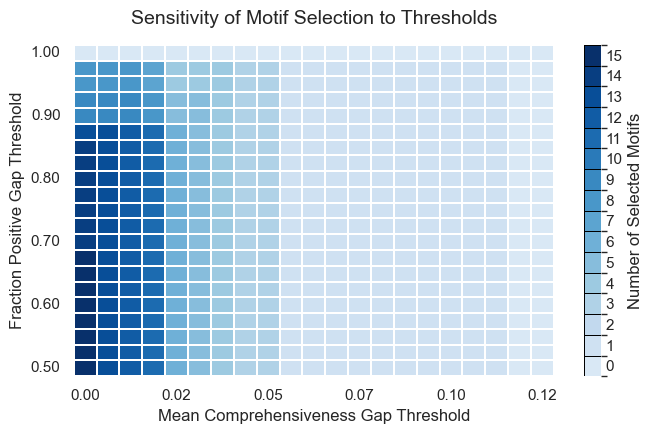

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Threshold ranges
mean_gaps = np.linspace(0, 0.12, 21)
frac_positives = np.linspace(0.5, 1.0, 21)

# Count selected motifs for each threshold combination
counts = np.zeros((len(frac_positives), len(mean_gaps)), dtype=int)

for i, fp in enumerate(frac_positives):
    for j, mg in enumerate(mean_gaps):
        selected = res[
            (res["q_value"] < 0.05) &
            (res["mean_gap"] >= mg) &
            (res["frac_positive"] > fp)
        ]
        counts[i, j] = len(selected)

# Create dataframe for heatmap
heatmap_df = pd.DataFrame(
    counts,
    index=np.round(frac_positives, 2),
    columns=np.round(mean_gaps, 3)
)

# Plot
sns.set_theme(style="white", font_scale=1.0)

fig, ax = plt.subplots(figsize=(7, 4.5))

from matplotlib.colors import BoundaryNorm, ListedColormap

# Discrete colors: one color for each possible motif count
max_count = int(counts.max())

cmap = ListedColormap(
    plt.get_cmap("Blues")(np.linspace(0.15, 1.0, max_count + 1))
)

norm = BoundaryNorm(
    np.arange(-0.5, max_count + 1.5, 1),
    cmap.N
)

sns.heatmap(
    heatmap_df,
    cmap=cmap,
    norm=norm,
    annot=False,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Number of Selected Motifs",
        "ticks": np.arange(0, max_count + 1, 1),
        "boundaries": np.arange(-0.5, max_count + 1.5, 1),
        "spacing": "uniform"
    },
    ax=ax
)
# Get colorbar
cbar = ax.collections[0].colorbar

# Draw visible boundaries between discrete colors
cbar.solids.set_edgecolor("black")
cbar.solids.set_linewidth(0.6)

# Keep integer labels, remove tick marks
cbar.ax.tick_params(length=0)

# Show fewer tick labels
ax.set_xticks(np.arange(0, 21, 4) + 0.5)
ax.set_xticklabels(
    [f"{x:.2f}" for x in mean_gaps[::4]],
    rotation=0
)

ax.set_yticks(np.arange(0, 21, 4) + 0.5)
ax.set_yticklabels(
    [f"{x:.2f}" for x in frac_positives[::4]],
    rotation=0
)

ax.invert_yaxis()

ax.set_xlabel("Mean Comprehensiveness Gap Threshold", fontsize=12)
ax.set_ylabel("Fraction Positive Gap Threshold", fontsize=12)
ax.set_title(
    "Sensitivity of Motif Selection to Thresholds",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()


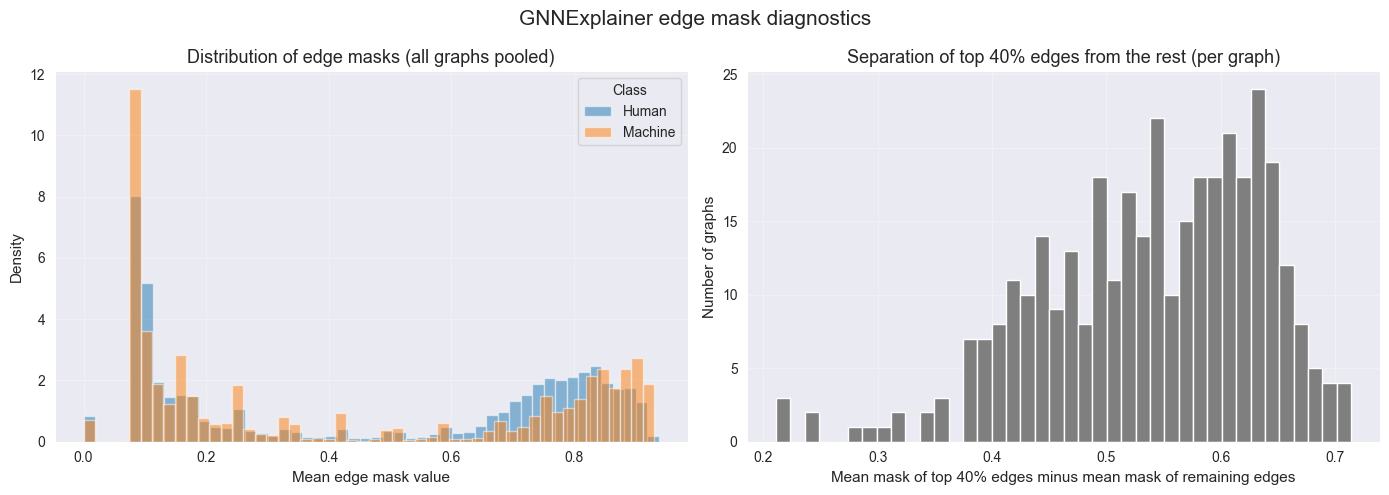

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torch

colors = {"Human": "tab:blue", "Machine": "tab:orange"}
f = 0.4  # fraction of top edges

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Pooled distribution of edge masks, per class
for cls, name in [(0, "Human"), (1, "Machine")]:
    m = torch.cat([r["edge_mask"] for r in results if r["label"] == cls]).numpy()
    ax[0].hist(m, bins=50, alpha=0.5, label=name, density=True, color=colors[name])

ax[0].set_title("Distribution of edge masks (all graphs pooled)", fontsize=13)
ax[0].set_xlabel("Mean edge mask value", fontsize=11)
ax[0].set_ylabel("Density", fontsize=11)
ax[0].legend(title="Class")
ax[0].grid(alpha=0.3)

# 2. Per-graph separation between top-f% edges and the rest
gaps = []
for r in results:
    m = np.sort(r["edge_mask"].numpy())[::-1]
    k = max(1, int(np.ceil(f * len(m))))
    gaps.append(m[:k].mean() - m[k:].mean() if k < len(m) else np.nan)
gaps = np.array(gaps)
gaps = gaps[~np.isnan(gaps)]

ax[1].hist(gaps, bins=40, color="tab:gray", edgecolor="white")
ax[1].set_title(f"Separation of top {f:.0%} edges from the rest (per graph)", fontsize=13)
ax[1].set_xlabel(f"Mean mask of top {f:.0%} edges minus mean mask of remaining edges", fontsize=11)
ax[1].set_ylabel("Number of graphs", fontsize=11)
ax[1].grid(alpha=0.3)

fig.suptitle("GNNExplainer edge mask diagnostics", fontsize=15)
plt.tight_layout()
plt.show()